# PLN Mobile Review Sentiment Analysis
### Phase 1 — Load & Explore

This notebook loads the review JSON files you scraped with the Play Store scraper app (from `data/`), combines them, and explores what we're working with before any cleaning or modeling.

**Setup:** place this notebook in your `playstore-reviews/` project folder (same level as `app.py` and `data/`), then run:
```
source venv/bin/activate
pip install jupyter pandas
jupyter notebook
```


In [ ]:
pip install pandas

   ---------------------------------------- 0.0/10.0 MB ? eta -:--:--
   ---------------------------------------- 0.1/10.0 MB 2.3 MB/s eta 0:00:05
    --------------------------------------- 0.2/10.0 MB 3.0 MB/s eta 0:00:04
   - -------------------------------------- 0.4/10.0 MB 3.2 MB/s eta 0:00:03
   -- ------------------------------------- 0.6/10.0 MB 3.5 MB/s eta 0:00:03
   --- ------------------------------------ 0.8/10.0 MB 3.8 MB/s eta 0:00:03
   ---- ----------------------------------- 1.1/10.0 MB 4.0 MB/s eta 0:00:03
   ----- ---------------------------------- 1.3/10.0 MB 4.2 MB/s eta 0:00:03
   ----- ---------------------------------- 1.5/10.0 MB 3.9 MB/s eta 0:00:03
   ------ --------------------------------- 1.7/10.0 MB 4.0 MB/s eta 0:00:03
   ------- -------------------------------- 1.8/10.0 MB 4.2 MB/s eta 0:00:02
   ------- -------------------------------- 1.8/10.0 MB 4.2 MB/s eta 0:00:02
   ------- -------------------------------- 1.9/10.0 MB 3.5 MB/s eta 0:00:03
   ---


[notice] A new release of pip is available: 24.0 -> 26.1.2
[notice] To update, run: python.exe -m pip install --upgrade pip


In [17]:
pip install matplotlib

     ---------------------------------------- 0.0/80.3 kB ? eta -:--:--
     ---------------------------------------- 80.3/80.3 kB 2.2 MB/s eta 0:00:00
  Using cached cycler-0.12.1-py3-none-any.whl.metadata (3.8 kB)
     ---------------------------------------- 0.0/121.0 kB ? eta -:--:--
     -------------------------------------- 121.0/121.0 kB 7.4 MB/s eta 0:00:00
   ---------------------------------------- 0.0/9.3 MB ? eta -:--:--
    --------------------------------------- 0.2/9.3 MB 6.3 MB/s eta 0:00:02
   -- ------------------------------------- 0.5/9.3 MB 5.9 MB/s eta 0:00:02
   --- ------------------------------------ 0.8/9.3 MB 5.4 MB/s eta 0:00:02
   ---- ----------------------------------- 1.0/9.3 MB 5.4 MB/s eta 0:00:02
   ----- ---------------------------------- 1.3/9.3 MB 6.1 MB/s eta 0:00:02
   ------- -------------------------------- 1.6/9.3 MB 6.2 MB/s eta 0:00:02
   -------- ------------------------------- 2.0/9.3 MB 6.1 MB/s eta 0:00:02
   --------- -----------------


[notice] A new release of pip is available: 24.0 -> 26.1.2
[notice] To update, run: python.exe -m pip install --upgrade pip


In [54]:
pip install sklearn

  Using cached sklearn-0.0.post12.tar.gz (2.6 kB)
  Installing build dependencies: started
  Installing build dependencies: finished with status 'done'
  Getting requirements to build wheel: started
  Getting requirements to build wheel: finished with status 'error'
Note: you may need to restart the kernel to use updated packages.


  error: subprocess-exited-with-error
  
  × Getting requirements to build wheel did not run successfully.
  │ exit code: 1
  ╰─> [15 lines of output]
      The 'sklearn' PyPI package is deprecated, use 'scikit-learn'
      rather than 'sklearn' for pip commands.
      
      Here is how to fix this error in the main use cases:
      - use 'pip install scikit-learn' rather than 'pip install sklearn'
      - replace 'sklearn' by 'scikit-learn' in your pip requirements files
        (requirements.txt, setup.py, setup.cfg, Pipfile, etc ...)
      - if the 'sklearn' package is used by one of your dependencies,
        it would be great if you take some time to track which package uses
        'sklearn' instead of 'scikit-learn' and report it to their issue tracker
      - as a last resort, set the environment variable
        SKLEARN_ALLOW_DEPRECATED_SKLEARN_PACKAGE_INSTALL=True to avoid this error
      
      More information is available at
      https://github.com/scikit-learn/sklearn-

In [8]:
import json
import os
import glob
import pandas as pd

pd.set_option("display.max_colwidth", 150) 

DATA_DIR = "data"  # relative to this notebook's location

## Load all scraped JSON files into one DataFrame

In [9]:
def load_all_reviews(data_dir=DATA_DIR, pattern="*.json"):
    files = glob.glob(os.path.join(data_dir, pattern))
    if not files:
        raise FileNotFoundError(f"No JSON files found in {data_dir}")

    all_rows = []
    for f in files:
        with open(f, "r", encoding="utf-8") as fh:
            payload = json.load(fh)

        meta = payload.get("meta", {})
        reviews = payload.get("reviews", [])

        for r in reviews:
            all_rows.append({
                "source_file": os.path.basename(f),
                "app_id": meta.get("app_id", meta.get("appId")),
                "review_id": r.get("reviewId"),
                "content": r.get("content"),
                "score": r.get("score"),
                "thumbs_up": r.get("thumbsUpCount"),
                "app_version": r.get("appVersion") or r.get("reviewCreatedVersion"),
                "at": r.get("at"),
                "reply_content": r.get("replyContent"),
            })

    df = pd.DataFrame(all_rows)
    print(f"Loaded {len(files)} file(s), {len(df)} total review rows.")
    return df

df = load_all_reviews()
df.head()

Loaded 2 file(s), 2000 total review rows.


,source_file,app_id,review_id,content,score,thumbs_up,app_version,at,reply_content
0,com.icon.pln123__stars-1__n1000__20260630-143858.json,com.icon.pln123,c3eb7523-a6d0-4c35-b608-f2667f78e3df,"Perbaiki bug yang sering terjadi saat login. lagi ngisi bagian pemasangan listrik aja ngulang lagi dari awal login, apalagi gak ada fitur open gal...",1,3,5.2.81,2026-06-16T12:37:13,Halo Kak Adisti. Mimin sangat memperhatikan fungsi fitur PLN Mobile agar dpt menyelaraskan dgn kebutuhan Plgn. Hal tsb jg akan jd noted buat mimin...
1,com.icon.pln123__stars-1__n1000__20260630-143858.json,com.icon.pln123,8ab2124a-c433-440c-94ee-54b7bed1149d,"nominal pengisian tidak fleksibel, lebih fleksibel aplikasi charge+, charge+ bisa mengisi sesuai kebutuhan, sedangkan PLN selalu menyisakan uang d...",1,5,5.2.81,2026-06-08T22:32:47,"Pagi Kak, kami tdk bermaksud mempersulit Kk. Ulasan dr Kk jd noted buat kami utk trs tingkatkan fitur layanan PLN Mobile agar lbh memudahkan plgn...."
2,com.icon.pln123__stars-1__n1000__20260630-143858.json,com.icon.pln123,2a2c1ed2-71b0-4112-9188-1bc65c8b800e,Aplikasinya logout sendiri. Terus pas login malah daftar ulang. Ada keterangan bisa gunakan email terdaftar agar masuk ke akun sebeumnya. Sudah di...,1,1,5.2.81,2026-06-18T10:53:51,Kami coba berikan solusi utk kendalanya ya Kak. Pastikan Kk login gunakan nmr ponsel yg terhubung dgn email tsb. Jika email Kk ingin ditautkan ke ...
3,com.icon.pln123__stars-1__n1000__20260630-143858.json,com.icon.pln123,b6571f17-6313-4924-8fa2-4933e255adde,"mau login saja susahnya minta ampun, nomor sudah terdaftar email sudah terdaftar pas masuk aplikasi masukkan nomor sudah, masukkan pin dari wa sud...",1,4,5.2.81,2026-06-14T05:26:41,"Pagi Kak. Mimin menyayangkan atas kendala yg seharusnya tdk terjadi. Merespon hal tsb, mhn Kk cb Clear Cache pd perangkat, Force Close apk & jaga ..."
4,com.icon.pln123__stars-1__n1000__20260630-143858.json,com.icon.pln123,b4245ff7-b335-40da-a1e2-fdb526f21baf,"aplikasi bagus sekali, sangat sulit seperti teka teki, layak untuk dimainkan untuk mengasah otak. untuk menghubungi live chat, selalu tidak bisa d...",1,3,5.2.81,2026-06-11T15:15:12,"Tks Kak Bastian, sdh menjadi Plgn setia PLN. Maaf bila Kk kesulitan utk masuk fitur Live Chat. Sbg info, PLN menyediakan beberapa alternatif pelay..."


## Basic shape & column check

In [10]:
df.shape

(2000, 9)

In [11]:
df.dtypes

source_file        str
app_id             str
review_id          str
content            str
score            int64
thumbs_up        int64
app_version        str
at                 str
reply_content      str
dtype: object

## Star score distribution
Since you scraped 1-star specifically, this should be mostly/all 1s — good sanity check.

In [12]:
df["score"].value_counts(dropna=False).sort_index()

score
1    1000
2    1000
Name: count, dtype: int64

## Missing or empty content

In [13]:
empty_mask = df["content"].isna() | (df["content"].astype(str).str.strip() == "")
print(f"Empty/missing content rows: {empty_mask.sum()}")
df[empty_mask].head()

Empty/missing content rows: 0


,source_file,app_id,review_id,content,score,thumbs_up,app_version,at,reply_content


## Duplicates

In [14]:
print(f"Duplicate review_id count: {df['review_id'].duplicated().sum()}")
print(f"Duplicate content count (exact text match): {df['content'].duplicated().sum()}")

df[df["content"].duplicated(keep=False)].sort_values("content").head(10)

Duplicate review_id count: 0
Duplicate content count (exact text match): 0


,source_file,app_id,review_id,content,score,thumbs_up,app_version,at,reply_content


## Review length distribution
Very short reviews (emoji-only, single word) are low-signal and worth flagging.

In [15]:
lengths = df["content"].astype(str).str.len()
lengths.describe()

count    2000.000000
mean      249.528500
std       116.627382
min        31.000000
25%       161.000000
50%       234.000000
75%       321.000000
max       500.000000
Name: content, dtype: float64

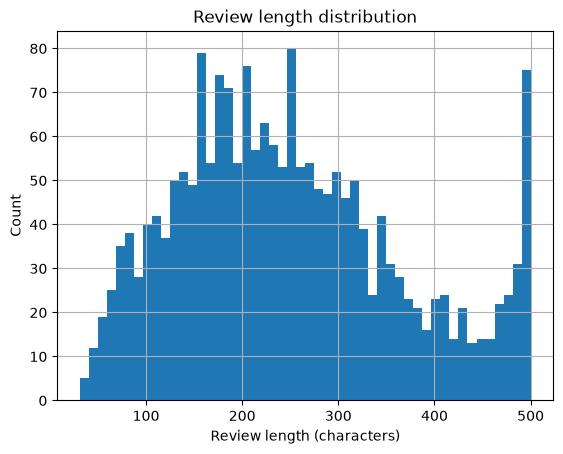

In [18]:
import matplotlib.pyplot as plt

lengths.hist(bins=50)
plt.xlabel("Review length (characters)")
plt.ylabel("Count")
plt.title("Review length distribution")
plt.show()

In [19]:
short = df[lengths <= 3]
print(f"Very short reviews (<=3 chars): {len(short)}")
short["content"].value_counts().head(10)

Very short reviews (<=3 chars): 0


Series([], Name: count, dtype: int64)

## Date range & app version spread

In [20]:
dates = pd.to_datetime(df["at"], errors="coerce")
print(f"From {dates.min()} to {dates.max()}")

df["app_version"].value_counts(dropna=False).head(10)

From 2018-10-05 23:01:25 to 2026-06-29 20:19:48


app_version
NaN       262
5.2.80    242
5.2.79    185
5.2.81    171
5.2.78     90
5.2.33     62
5.0.32     58
5.2.47     55
5.2.26     39
5.2.66     38
Name: count, dtype: int64

## Eyeball some real samples
This is the most important cell in this notebook — actually read the text. Look for: language (ID/EN/mixed), slang density, emoji use, whether 1-star reviews are really complaints or just misclicks/unrelated gripes.

In [21]:
for _, row in df.sample(15, random_state=42).iterrows():
    print(f"[{row['score']}★] {row['content']}")
    print("-" * 80)

[2★] Sya download aplikasi ini knp no hp,email bsa ada yg rubah ya? gk aman ini aplikasi nya cek profile semua sudah berubah n ada pmbritauan dr email jg.jd sya delet ini aplikasinya mengerikan bener.
--------------------------------------------------------------------------------
[1★] Saya mau Login di aplikasi PLN Mobile pakai nomer HP begitu klik Lanjutkan tidak ada respon di tgl 1 Mei 2026 pukul 15.32 WIB. Klik fitur Live Chat tidak ada respon, Klik Pelajari disini untuk coba Login pakai Akun Google hasilnya Data Not Found. Koneksi Internet Saya stabil dan sangat lancar disaat coba aplikasi ini pakai WiFi rumah Saya dan pakai DATA Internet di HP Saya. Ini Saya coba di HP Android 15 di device Xiaomi 15.
--------------------------------------------------------------------------------
[2★] Secara sistem sudah bagus dan mudah diakses, akan tetapi kemarin ada kendala tidak bisa melakukan pembayaran dan coba pakai live chat tapi sistem live chat nya nggak jelas dan arahan dari cs nya jug

## Save combined dataset
This CSV becomes the input for Phase 2 (text cleaning + slang normalization).

In [ ]:
# df.to_csv("combined_reviews.csv", index=False)
# print("Saved combined_reviews.csv")

---
# Phase 2 — Text Cleaning & Normalization

Goal: turn messy raw review text into something a lexicon or model can actually score well.

We'll do this in layers, and check the output at each layer before moving to the next:
1. Basic cleaning (lowercase, strip URLs/punctuation/numbers)
2. Slang normalization (Indonesian informal → baku/formal words)
3. Stopword removal (using Sastrawi)
4. Stemming (using Sastrawi) — optional, see note below

**Note on stemming:** stemming is useful for the lexicon-based approach (Phase 3) since lexicons are usually built on root words. But if we later use a pretrained IndoBERT model (Phase 4), we should feed it the *unstemmed* text — transformer models expect natural language, not stemmed fragments. So we'll keep both a `clean_stemmed` and `clean_unstemmed` column.

In [22]:
!pip install PySastrawi -q


[notice] A new release of pip is available: 24.0 -> 26.1.2
[notice] To update, run: python.exe -m pip install --upgrade pip


In [23]:
import re
# import pandas as pd

# df = pd.read_csv("combined_reviews.csv")
# df.shape

## Step 1 — Basic cleaning

In [24]:
def clean_text(text):
    text = str(text).lower()
    text = re.sub(r"http\S+|www\S+", " ", text)          # remove URLs
    text = re.sub(r"[^a-z\s]", " ", text)                 # keep only letters
    text = re.sub(r"\s+", " ", text).strip()              # collapse whitespace
    return text

df["clean"] = df["content"].apply(clean_text)
df[["content", "clean"]].sample(5, random_state=1)

,content,clean
674,"Sudah bayar, tapi sudah 3 hari token tidak muncul. Lalu saya cek riwayat transaksi, keterangannya malah pembayaran kadaluwarsa padahal saya langsu...",sudah bayar tapi sudah hari token tidak muncul lalu saya cek riwayat transaksi keterangannya malah pembayaran kadaluwarsa padahal saya langsung ba...
1699,Saya baru coba danKata nya apk ini bagus.. Tp bukti nya mana.. saya mau mengadu kan masalah kwh ada tulisan PERIKSA ga bisa2 dan susah ga bisa di ...,saya baru coba dankata nya apk ini bagus tp bukti nya mana saya mau mengadu kan masalah kwh ada tulisan periksa ga bisa dan susah ga bisa di klik ...
1282,Suka mati listrik 1bulan bisa 5 kali Dan PLN dari dulu tidak berkembang menuju era digital ( harus nya Pelanggan beli token itu bisa dimasukkan ta...,suka mati listrik bulan bisa kali dan pln dari dulu tidak berkembang menuju era digital harus nya pelanggan beli token itu bisa dimasukkan tanpa h...
1315,Awal download tanpa biaya tambahan Sekarang sudah ada biaya tambahan Saldo terpotong tapi token tidak muncul Sistem merespon komplain lama Keburu ...,awal download tanpa biaya tambahan sekarang sudah ada biaya tambahan saldo terpotong tapi token tidak muncul sistem merespon komplain lama keburu ...
1210,tidak bisa mendapat balesan email saat akan verifikasi pendaftran akun,tidak bisa mendapat balesan email saat akan verifikasi pendaftran akun


## Step 2 — Slang normalization

This starter dictionary covers common patterns seen in Indonesian app reviews. **Extend this as you read more of your data** — every new slang word you spot in the sample cells below, add it here. This dictionary is the single highest-leverage thing you can improve in this whole pipeline.

In [25]:
slang_dict = {
    "gak": "tidak", "ga": "tidak", "g": "tidak", "gk": "tidak", "tdk": "tidak",
    "yg": "yang", "dgn": "dengan", "utk": "untuk", "bgt": "banget", "sm": "sama",
    "bs": "bisa", "gabisa": "tidak bisa", "gbs": "tidak bisa", "udh": "sudah",
    "udah": "sudah", "sdh": "sudah", "blm": "belum", "trs": "terus", "dr": "dari",
    "krn": "karena", "karna": "karena", "jd": "jadi", "jgn": "jangan",
    "aja": "saja", "aj": "saja", "tp": "tapi", "tuh": "itu", "gt": "begitu",
    "gitu": "begitu", "eror": "error", "erorr": "error", "lemot": "lambat",
    "apk": "aplikasi", "app": "aplikasi", "byr": "bayar", "dpt": "dapat",
    "dapet": "dapat", "knp": "kenapa", "napa": "kenapa", "min": "admin",
    "pls": "tolong", "please": "tolong", "ngga": "tidak", "nggak": "tidak",
    "kalo": "kalau", "klo": "kalau", "gmn": "bagaimana", "gimana": "bagaimana",
    "org": "orang", "skrg": "sekarang", "sy": "saya", "sya": "saya",
    "kzl": "kesal", "males": "malas", "mager": "malas", "lg": "lagi",
}

def normalize_slang(text, slang_dict=slang_dict):
    words = text.split()
    return " ".join(slang_dict.get(w, w) for w in words)

df["clean_unstemmed"] = df["clean"].apply(normalize_slang)
df[["content", "clean_unstemmed"]].sample(5, random_state=1)

,content,clean_unstemmed
674,"Sudah bayar, tapi sudah 3 hari token tidak muncul. Lalu saya cek riwayat transaksi, keterangannya malah pembayaran kadaluwarsa padahal saya langsu...",sudah bayar tapi sudah hari token tidak muncul lalu saya cek riwayat transaksi keterangannya malah pembayaran kadaluwarsa padahal saya langsung ba...
1699,Saya baru coba danKata nya apk ini bagus.. Tp bukti nya mana.. saya mau mengadu kan masalah kwh ada tulisan PERIKSA ga bisa2 dan susah ga bisa di ...,saya baru coba dankata nya aplikasi ini bagus tapi bukti nya mana saya mau mengadu kan masalah kwh ada tulisan periksa tidak bisa dan susah tidak ...
1282,Suka mati listrik 1bulan bisa 5 kali Dan PLN dari dulu tidak berkembang menuju era digital ( harus nya Pelanggan beli token itu bisa dimasukkan ta...,suka mati listrik bulan bisa kali dan pln dari dulu tidak berkembang menuju era digital harus nya pelanggan beli token itu bisa dimasukkan tanpa h...
1315,Awal download tanpa biaya tambahan Sekarang sudah ada biaya tambahan Saldo terpotong tapi token tidak muncul Sistem merespon komplain lama Keburu ...,awal download tanpa biaya tambahan sekarang sudah ada biaya tambahan saldo terpotong tapi token tidak muncul sistem merespon komplain lama keburu ...
1210,tidak bisa mendapat balesan email saat akan verifikasi pendaftran akun,tidak bisa mendapat balesan email saat akan verifikasi pendaftran akun


## Step 3 — Stopword removal + Step 4 — Stemming (Sastrawi)

In [26]:
from Sastrawi.Stemmer.StemmerFactory import StemmerFactory
from Sastrawi.StopWordRemover.StopWordRemoverFactory import StopWordRemoverFactory

stopword_remover = StopWordRemoverFactory().create_stop_word_remover()
stemmer = StemmerFactory().create_stemmer()

def remove_stopwords(text):
    return stopword_remover.remove(text)

def stem_text(text):
    return stemmer.stem(text)

# Sastrawi's stemmer is slow on large datasets since it's not vectorized —
# this may take a few minutes on 1000 rows. Grab a coffee.
df["no_stopwords"] = df["clean_unstemmed"].apply(remove_stopwords)
df["clean_stemmed"] = df["no_stopwords"].apply(stem_text)

df[["content", "clean_unstemmed", "clean_stemmed"]].sample(5, random_state=1)

,content,clean_unstemmed,clean_stemmed
674,"Sudah bayar, tapi sudah 3 hari token tidak muncul. Lalu saya cek riwayat transaksi, keterangannya malah pembayaran kadaluwarsa padahal saya langsu...",sudah bayar tapi sudah hari token tidak muncul lalu saya cek riwayat transaksi keterangannya malah pembayaran kadaluwarsa padahal saya langsung ba...,bayar token muncul cek riwayat transaksi terang bayar kadaluwarsa bayar beli token pln mobile tolong ditindaklanjuti refund kirim adu lanjut
1699,Saya baru coba danKata nya apk ini bagus.. Tp bukti nya mana.. saya mau mengadu kan masalah kwh ada tulisan PERIKSA ga bisa2 dan susah ga bisa di ...,saya baru coba dankata nya aplikasi ini bagus tapi bukti nya mana saya mau mengadu kan masalah kwh ada tulisan periksa tidak bisa dan susah tidak ...,coba dankata aplikasi bagus bukti adu kwh tulis periksa susah klik adu bener bagus ksh bintang
1282,Suka mati listrik 1bulan bisa 5 kali Dan PLN dari dulu tidak berkembang menuju era digital ( harus nya Pelanggan beli token itu bisa dimasukkan ta...,suka mati listrik bulan bisa kali dan pln dari dulu tidak berkembang menuju era digital harus nya pelanggan beli token itu bisa dimasukkan tanpa h...,suka mati listrik pln kembang era digital langgan beli token masuk ketik nomor angka kwh meter masuk online aplikasi pln mobil dunia kembang rumah...
1315,Awal download tanpa biaya tambahan Sekarang sudah ada biaya tambahan Saldo terpotong tapi token tidak muncul Sistem merespon komplain lama Keburu ...,awal download tanpa biaya tambahan sekarang sudah ada biaya tambahan saldo terpotong tapi token tidak muncul sistem merespon komplain lama keburu ...,download biaya tambah biaya tambah saldo potong token muncul sistem merespon komplain keburu listrik padam tindak token bayar direspon cepat thank
1210,tidak bisa mendapat balesan email saat akan verifikasi pendaftran akun,tidak bisa mendapat balesan email saat akan verifikasi pendaftran akun,balesan email verifikasi pendaftran akun


## Sanity check — before vs after, full pipeline

In [27]:
for _, row in df.sample(10, random_state=7).iterrows():
    print("RAW    :", row["content"])
    print("UNSTEM :", row["clean_unstemmed"])
    print("STEMMED:", row["clean_stemmed"])
    print("-" * 80)

RAW    : apk reseh !!! minta update mulu, cuman buat swascan, dah diupdate upacara macam² untuk masuk lagi, benar² apk reseh
UNSTEM : aplikasi reseh minta update mulu cuman buat swascan dah diupdate upacara macam untuk masuk lagi benar aplikasi reseh
STEMMED: aplikasi reseh update mulu cuman swascan dah diupdate upacara aplikasi reseh
--------------------------------------------------------------------------------
RAW    : ini kenapa apk PLN mobile beberapa hari ini susah banget untuk buat laporan listrik padam, paket sudah di isi bahkan sampai di hotspot tapi tetap gak bisa buat laporan, mohon di perbaiki untuk apk nya boss pln
UNSTEM : ini kenapa aplikasi pln mobile beberapa hari ini susah banget untuk buat laporan listrik padam paket sudah di isi bahkan sampai di hotspot tapi tetap tidak bisa buat laporan mohon di perbaiki untuk aplikasi nya boss pln
STEMMED: aplikasi pln mobile susah banget lapor listrik padam paket isi hotspot lapor baik aplikasi boss pln
-------------------------

## Check for rows that became empty after cleaning
Some reviews are just emojis/numbers/punctuation — after cleaning they'll be blank. Worth knowing how many, and deciding whether to drop them or keep the raw emoji as a separate signal later.

In [28]:
empty_after_clean = df[df["clean_unstemmed"].str.strip() == ""]
print(f"Rows empty after cleaning: {len(empty_after_clean)}")
empty_after_clean[["content"]].head(10)

Rows empty after cleaning: 0


,content


## Save cleaned dataset
This becomes the input for Phase 3 (sentiment scoring).

In [ ]:
# df.to_csv("cleaned_reviews.csv", index=False)
# print("Saved cleaned_reviews.csv")
# df.columns.tolist()

---
# Phase 3 — Lexicon-based Sentiment Scoring

Goal: score each review's sentiment using an Indonesian sentiment lexicon (word list with polarity weights) — no training data needed. Then compare it against the star rating you already have, since disagreements between the two are often the most interesting rows in your dataset.

We'll use **InSet**, a public Indonesian sentiment lexicon (Fajri Koto et al.), which has ~3600 positive and ~6600 negative words with weights.

**Input:** `cleaned_reviews.csv` from Phase 2
**Output:** `scored_reviews.csv` — same data + `lexicon_score` and `lexicon_label` columns

## Step 1 — Download the InSet lexicon
Run once. It saves two small files locally so you don't need internet access every run.

In [29]:
import urllib.request
import os

if not os.path.exists("positive.tsv"):
    urllib.request.urlretrieve(
        "https://raw.githubusercontent.com/fajri91/InSet/master/positive.tsv",
        "positive.tsv"
    )
if not os.path.exists("negative.tsv"):
    urllib.request.urlretrieve(
        "https://raw.githubusercontent.com/fajri91/InSet/master/negative.tsv",
        "negative.tsv"
    )

print("Lexicon files ready.")

Lexicon files ready.


## Step 2 — Build the lexicon dictionary

A few notes on why this isn't a totally naive lookup:
- Some words appear in **both** the positive and negative lists (context-dependent words in the original news-domain corpus this lexicon was built from). We **sum** their weights rather than blindly overwrite, so genuinely ambiguous words net toward zero instead of randomly picking whichever file loads last.
- We only keep **single-word** entries for this simple lookup (the files also have multi-word phrases like "putus tali gantung" — matching those properly needs phrase detection, which we're skipping for this first pass).
- A handful of **domain-neutral words get mis-scored** by a lexicon built on general news text — e.g. `aplikasi`, `admin`, `listrik`, `token` come back with nonzero sentiment weight in InSet even though they're just neutral nouns in our PLN Mobile context. We override those to 0. **Check the sanity-check cell below and add more overrides if you spot other domain nouns getting wrongly scored.**

In [30]:
import pandas as pd

pos = pd.read_csv("positive.tsv", sep="\t")
neg = pd.read_csv("negative.tsv", sep="\t")

lexicon = {}
for _, row in pos.iterrows():
    w = str(row["word"]).strip()
    if " " not in w:
        lexicon[w] = lexicon.get(w, 0.0) + float(row["weight"])
for _, row in neg.iterrows():
    w = str(row["word"]).strip()
    if " " not in w:
        lexicon[w] = lexicon.get(w, 0.0) + float(row["weight"])

# Domain-neutral overrides — extend this list as you spot more false positives/negatives
domain_neutral = [
    "aplikasi", "apk", "app", "admin", "hp", "update", "pln",
    "listrik", "token", "saja", "biasa", "nya",
]
for w in domain_neutral:
    lexicon[w] = 0.0

print(f"Lexicon size: {len(lexicon)} words")

Lexicon size: 8404 words


## Step 3 — Load cleaned data and score each review

In [31]:
def score_text(text, lexicon=lexicon):
    words = str(text).split()
    if not words:
        return 0.0
    return sum(lexicon.get(w, 0.0) for w in words)

# Using clean_unstemmed rather than clean_stemmed: stemming can strip
# meaningful prefixes/suffixes that change a word's lexicon match.
# Try clean_stemmed too and compare — whichever matches more words in
# the lexicon (see coverage check below) is the better choice for your data.
df["lexicon_score"] = df["clean_unstemmed"].apply(score_text)
df[["content", "clean_unstemmed", "lexicon_score"]].sample(10, random_state=3)

,content,clean_unstemmed,lexicon_score
933,"Meski aplikasi sedikit membantu, kinerja aplikasi sangat lambat, banyak bagian dr aplikasi terpotong, seperti tampilan ikon menu layanan, keterang...",meski aplikasi sedikit membantu kinerja aplikasi sangat lambat banyak bagian dari aplikasi terpotong seperti tampilan ikon menu layanan keterangan...,-38.0
1459,"Bulan ini fitur pembayaran tidak dapat di akses, ada kendala tidak dpt menggunakan fitur pembayaran listrik bulanan. Ok lu dah bisa di pake kembal...",bulan ini fitur pembayaran tidak dapat di akses ada kendala tidak dapat menggunakan fitur pembayaran listrik bulanan ok lu dah bisa di pake kembal...,-7.0
1338,"Refund dana Iconnect yg lama, sampe saat ini belum ada respon. Padahal bukan kesalahan customer tapi memang area coveragenya agak jauh. Seharusnya...",refund dana iconnect yang lama sampe saat ini belum ada respon padahal bukan kesalahan customer tapi memang area coveragenya agak jauh seharusnya ...,-35.0
1802,"Saya tiba tiba tidak bisa buka aplikasi, tertulis saya menggunakan aplikasi root, emulator atau mode pengembang. Padahal saya tidak melakukan peru...",saya tiba tiba tidak bisa buka aplikasi tertulis saya menggunakan aplikasi root emulator atau mode pengembang padahal saya tidak melakukan perubah...,-15.0
263,Mau daftar aja susah banget. Email kode verifikasi terlambat melebihi batas waktu,mau daftar saja susah banget email kode verifikasi terlambat melebihi batas waktu,-6.0
81,"sudah mengajukan pengaduan kWh meter periksa, dan sudah mengikuti setiap tahapannya, kenapa selalu balasannya pengaduan tidak valid. kenapa dengan...",sudah mengajukan pengaduan kwh meter periksa dan sudah mengikuti setiap tahapannya kenapa selalu balasannya pengaduan tidak valid kenapa dengan ap...,-4.0
339,"Penanganan sangat-sangat lambat. Setelah 12 jam dari pelaporan baru ditanggapi. Dulu thn 24, respon & penanganan sangat cepat, skg leletnya bukan ...",penanganan sangat sangat lambat setelah jam dari pelaporan baru ditanggapi dulu thn respon penanganan sangat cepat skg leletnya bukan main pdhl bumn,-7.0
805,percuma lapor cuma buat panjangan aja gak ada tindakan nyata🙄,percuma lapor cuma buat panjangan saja tidak ada tindakan nyata,1.0
69,"untuk masyarakat Indonesia, Hati-hati yg mau pasang baru meteran/kwh listrik disini, aplikasi ini penipu, karna saya sudah 2bulan lebih sampai sek...",untuk masyarakat indonesia hati hati yang mau pasang baru meteran kwh listrik disini aplikasi ini penipu karena saya sudah bulan lebih sampai seka...,-20.0
685,Bintang 1. Respon lambat tidak maksimal dalam menerima pengaduan. Tidak ada konfirmasi tindak lanjutnya hanya disuruh menunggu. Unit PLNnya pun ti...,bintang respon lambat tidak maksimal dalam menerima pengaduan tidak ada konfirmasi tindak lanjutnya hanya disuruh menunggu unit plnnya pun tidak a...,-12.0


## Step 4 — Convert score to a label

Thresholds matter here — start with these, then adjust based on the distribution and sanity checks below.

In [32]:
POS_THRESH = 1.0
NEG_THRESH = -1.0

def label_from_score(score, pos_thresh=POS_THRESH, neg_thresh=NEG_THRESH):
    if score > pos_thresh:
        return "positive"
    elif score < neg_thresh:
        return "negative"
    else:
        return "neutral"

df["lexicon_label"] = df["lexicon_score"].apply(label_from_score)
df["lexicon_label"].value_counts()

lexicon_label
negative    1753
positive     143
neutral      104
Name: count, dtype: int64

## Lexicon coverage check

If most words in your reviews aren't found in the lexicon at all, the score is meaningless (it'll just hover near 0 / "neutral" for everything). Worth checking before trusting the output.

In [33]:
def coverage(text, lexicon=lexicon):
    words = str(text).split()
    if not words:
        return 0.0
    matched = sum(1 for w in words if w in lexicon)
    return matched / len(words)

df["lexicon_coverage"] = df["clean_unstemmed"].apply(coverage)
print(f"Average word coverage: {df['lexicon_coverage'].mean():.1%}")
df["lexicon_coverage"].describe()

Average word coverage: 50.3%


count    2000.000000
mean        0.502648
std         0.103450
min         0.125000
25%         0.435897
50%         0.500000
75%         0.564516
max         1.000000
Name: lexicon_coverage, dtype: float64

## Step 5 — Compare against star rating

Turn the star rating into a simple label so we can cross-check. Remember: your dataset is currently all/mostly 1-star, so this comparison is really asking *"does the text actually sound negative, or was the 1-star about something else (e.g. unrelated complaint, misclick, or feature request disguised as a low rating)?"*

In [34]:
def star_to_label(score):
    if score <= 2:
        return "negative"
    elif score == 3:
        return "neutral"
    else:
        return "positive"

df["star_label"] = df["score"].apply(star_to_label)

pd.crosstab(df["star_label"], df["lexicon_label"])

lexicon_label,negative,neutral,positive
star_label,,,
negative,1753,104,143


## Step 6 — Look at the disagreements

These are the most useful rows in your whole dataset — 1-star reviews where the lexicon says the *text itself* doesn't read negative. Read through these; they often reveal complaints that aren't really about the app being bad (e.g. "aplikasi bagus tapi tolong tambah fitur transfer token").

In [35]:
disagreements = df[(df["star_label"] == "negative") & (df["lexicon_label"] != "negative")]
print(f"Low Star reviews where text doesn't read negative: {len(disagreements)} ({len(disagreements)/len(df):.1%})")

for _, row in disagreements.sample(min(10, len(disagreements)), random_state=1).iterrows():
    print(f"[{row['score']}★, lexicon={row['lexicon_label']}, score={row['lexicon_score']}] {row['content']}")
    print("-" * 80)

Low Star reviews where text doesn't read negative: 247 (12.3%)
[1★, lexicon=neutral, score=-1.0] nelpon oln 123 kebanyakan intronya sampe pulsa 5rb abis buat intro doang.
--------------------------------------------------------------------------------
[2★, lexicon=positive, score=9.0] Udah dibayar untk langganan wifi malah udh smpai 15hri belum dipasang2 .. bilang alasan modem habis .. dari kemarin sebelum bayar ya bilang donk kalo modem habis . Nggak carainya pelanggan udh byr masih nunggu berhari2 bhkn berminggu2 .. awal aja udh bikin kapok pelanggan . Apalagi seterusnya ..
--------------------------------------------------------------------------------
[2★, lexicon=positive, score=20.0] Program diskon 50% Januari Februari 2025 untuk pembelian token listrik sepertinya PLN belom siap. Aplikasi pembelian token baik melalui PLN mobile / marketplace sulit di akses. Apakah server down. Masa sekelas BUMN Besar msh punya kendala seperti ini. Hayolah kalo mau kasih promo dibarengin dengan ku

In [36]:
negative_lex = df[(df["star_label"] == "negative") & (df["lexicon_label"] == "negative")]
print(f"Low Star reviews where text read negative: {len(negative_lex)} ({len(negative_lex)/len(df):.1%})")

for _, row in negative_lex.sample(min(10, len(negative_lex)), random_state=1).iterrows():
    print(f"[{row['score']}★, lexicon={row['lexicon_label']}, score={row['lexicon_score']}] {row['content']}")
    print("-" * 80)

Low Star reviews where text read negative: 1753 (87.6%)
[2★, lexicon=negative, score=-29.0] Untuk pembayaran dll sih ok cuma saat pesang baru yg bikin kecewa kita sudah lunas semua dan tinggal tunggu pasang, setalah nunggu lama akhirnya datang pihak pasang dan gak di ACC karena aplikasi katanya gak tahu kondisi rumah,, ribet dah pokoknyaa,,,
--------------------------------------------------------------------------------
[2★, lexicon=negative, score=-33.0] Pengajuan masalah tagihan pembayaran di aplikasi laporan nya selesai....padahal belum ada petugas yg datang untuk koreksi dan tagihan nya masih belum berubah....tagihan nya ga wajar.....sampe tgl 24/8/2022 belum ada petugas yg Dateng juga buat ngecek
--------------------------------------------------------------------------------
[1★, lexicon=negative, score=-39.0] aplikasi yg sangat buruk, saya sudah 2 x daftar listrik baru, titik yg saya daftarkan dengan yg tersimpan selalu berbeda. klo blom siap buat aplikasi jangan dipaksakan, ak

In [37]:
positive_lex = df[(df["star_label"] == "negative") & (df["lexicon_label"] == "positive")]
print(f"Low Star reviews where text read positive: {len(positive_lex)} ({len(positive_lex)/len(df):.1%})")

for _, row in positive_lex.sample(min(10, len(positive_lex)), random_state=1).iterrows():
    print(f"[{row['score']}★, lexicon={row['lexicon_label']}, score={row['lexicon_score']}] {row['content']}")
    print("-" * 80)

Low Star reviews where text read positive: 143 (7.1%)
[2★, lexicon=positive, score=6.0] ahk aplikasi kaga jelas mau tarik saldo aja nunggu 5 hari kerja, aplikasi kok bukan mempermudah malah sama aja kaya kelakuan pegawainya!!!
--------------------------------------------------------------------------------
[2★, lexicon=positive, score=5.0] Jaringan internet iconnet ini kalau gangguan bisa berhari-hari. Customer servis slow respon. Terus teknisinya baru mau datang saat jaringan sudah normal. Hufffttt
--------------------------------------------------------------------------------
[1★, lexicon=positive, score=5.0] saya membeli token listrik dengan pembayaran melalui dana,,sudah melakukan transaksi saldo dana saya sudah dipotong namun status pembayarannya gagal,,kalo transaksi gagal tapi kenapa saldo saya hilang??
--------------------------------------------------------------------------------
[1★, lexicon=positive, score=7.0] aplikasi sering error.. pembelian token dana sudah dipotong na

## Score distribution — visualize

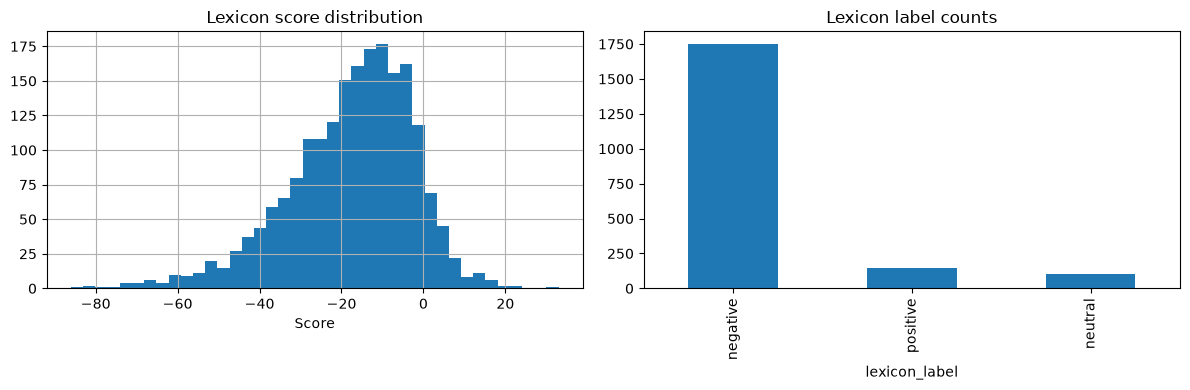

In [38]:
import matplotlib.pyplot as plt

fig, axes = plt.subplots(1, 2, figsize=(12, 4))

df["lexicon_score"].hist(bins=40, ax=axes[0])
axes[0].set_title("Lexicon score distribution")
axes[0].set_xlabel("Score")

df["lexicon_label"].value_counts().plot(kind="bar", ax=axes[1])
axes[1].set_title("Lexicon label counts")

plt.tight_layout()
plt.show()

## Step 7 — Save results

This becomes input for Phase 4 (transformer model, if you decide you need higher accuracy) and Phase 5 (topic/keyword analysis on the negative cluster).

In [ ]:
# df.to_csv("scored_reviews.csv", index=False)
# print("Saved scored_reviews.csv")
# df.columns.tolist()

---
# Phase 4 — IndoBERT Sentiment Classification

Goal: replace the lexicon's bag-of-words scoring with a transformer model that actually reads sentences in context — so negation, modifiers, and word order matter, not just presence/absence of "sentiment words".

**Model:** `w11wo/indonesian-roberta-base-sentiment-classifier` — an Indonesian RoBERTa model fine-tuned on the SmSA sentiment dataset (positive / neutral / negative), pulled from Hugging Face. No training needed on your end, just inference.

**Input:** `cleaned_reviews.csv` from Phase 2 (we'll use the original `content`, lightly cleaned, not the stemmed/stopword-stripped version — the model needs natural sentence structure to do its job)
**Output:** `indobert_scored_reviews.csv`

**Note:** the first time you run the download cell, it needs internet access to pull the model (~500MB) from Hugging Face. After that it's cached locally and works offline.

## Step 1 — Install dependencies
Run once.

In [1]:
!pip install transformers torch

     ---------------------------------------- 0.0/41.6 kB ? eta -:--:--
     ---------------------------------------- 41.6/41.6 kB 2.0 MB/s eta 0:00:00
  Using cached tokenizers-0.22.2-cp39-abi3-win_amd64.whl.metadata (7.4 kB)
  Using cached safetensors-0.8.0-cp310-abi3-win_amd64.whl.metadata (4.2 kB)
     ---------------------------------------- 0.0/57.3 kB ? eta -:--:--
     ---------------------------------------- 57.3/57.3 kB 1.5 MB/s eta 0:00:00
  Using cached sympy-1.14.0-py3-none-any.whl.metadata (12 kB)
  Using cached jinja2-3.1.6-py3-none-any.whl.metadata (2.9 kB)
  Using cached click-8.4.2-py3-none-any.whl.metadata (2.6 kB)
  Using cached mpmath-1.3.0-py3-none-any.whl.metadata (8.6 kB)
  Using cached mdurl-0.1.2-py3-none-any.whl.metadata (1.6 kB)
   ---------------------------------------- 0.0/11.6 MB ? eta -:--:--
   ---------------------------------------- 0.1/11.6 MB 6.4 MB/s eta 0:00:02
   - -------------------------------------- 0.4/11.6 MB 4.6 MB/s eta 0:00:03
   - ----


[notice] A new release of pip is available: 24.0 -> 26.1.2
[notice] To update, run: python.exe -m pip install --upgrade pip


In [ ]:
# pip install "transformers==4.46.3" --force-reinstall --no-deps

Defaulting to user installation because normal site-packages is not writeable
   ---------------------------------------- 0.0/10.0 MB ? eta -:--:--
   --- ------------------------------------ 0.8/10.0 MB 6.7 MB/s eta 0:00:02
   -------- ------------------------------- 2.1/10.0 MB 5.6 MB/s eta 0:00:02
   ----------- ---------------------------- 2.9/10.0 MB 5.1 MB/s eta 0:00:02
   --------------- ------------------------ 3.9/10.0 MB 5.0 MB/s eta 0:00:02
   ------------------- -------------------- 5.0/10.0 MB 5.0 MB/s eta 0:00:02
   ------------------------ --------------- 6.0/10.0 MB 5.1 MB/s eta 0:00:01
   ----------------------------- ---------- 7.3/10.0 MB 5.3 MB/s eta 0:00:01
   --------------------------------- ------ 8.4/10.0 MB 5.3 MB/s eta 0:00:01
   ------------------------------------- -- 9.4/10.0 MB 5.3 MB/s eta 0:00:01
   ---------------------------------------- 10.0/10.0 MB 5.1 MB/s  0:00:01
  Attempting uninstall: transformers
    Found existing installation: transformers 5


[notice] A new release of pip is available: 26.1.1 -> 26.1.2
[notice] To update, run: python.exe -m pip install --upgrade pip


In [2]:
import torch, transformers
from transformers.utils import is_torch_available

print("torch version:", torch.__version__)
print("transformers version:", transformers.__version__)
print("transformers thinks torch is available:", is_torch_available())

e:\BERKEMBANG\2 WEB\playstore-reviews\appreviewvenv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


torch version: 2.13.0+cpu
transformers version: 5.14.1
transformers thinks torch is available: True


## Step 2 — Load the model

This downloads and caches the model on first run. If this specific model ID doesn't load (Hugging Face model availability occasionally shifts), try the alternative commented out below — it's trained on the same underlying dataset (SmSA) and is a reliable fallback.

In [3]:
from transformers import pipeline

MODEL_NAME = "w11wo/indonesian-roberta-base-sentiment-classifier"
# Fallback if the above doesn't load:
# MODEL_NAME = "mdhugol/indonesia-bert-sentiment-classification"

device = 0 if torch.cuda.is_available() else -1
print(f"Using {'GPU' if device == 0 else 'CPU'}")

sentiment_pipe = pipeline(
    "text-classification",
    model=MODEL_NAME,
    tokenizer=MODEL_NAME,
    device=device,
    truncation=True,
    max_length=256
)

print("Model loaded.")

Using CPU


e:\BERKEMBANG\2 WEB\playstore-reviews\appreviewvenv\Lib\site-packages\huggingface_hub\file_download.py:139: UserWarning: `huggingface_hub` cache-system uses symlinks by default to efficiently store duplicated files but your machine does not support them in C:\Users\ASUS\.cache\huggingface\hub\models--w11wo--indonesian-roberta-base-sentiment-classifier. Caching files will still work but in a degraded version that might require more space on your disk. This warning can be disabled by setting the `HF_HUB_DISABLE_SYMLINKS_WARNING` environment variable. For more details, see https://huggingface.co/docs/huggingface_hub/how-to-cache#limitations.
To support symlinks on Windows, you either need to activate Developer Mode or to run Python as an administrator. In order to activate developer mode, see this article: https://docs.microsoft.com/en-us/windows/apps/get-started/enable-your-device-for-development
  warnings.warn(message)
Loading weights: 100%|██████████| 201/201 [00:00<00:00, 5765.78it/s

Model loaded.


## Step 3 — Sanity check on the disagreement examples from Phase 3

Before running this on all 1000 reviews, let's check it against the exact examples where the lexicon failed — especially the negation case (`"Belum Ada Fitur... kurang bermanfaat"`, scored +33 by the lexicon).

In [4]:
test_reviews = [
    "Belum Ada Fitur Top Up Saldo langsung membuat aplikasi BUMN ini kurang bermanfaat bagi pelanggan",
    "Pada saat mau pembayaran otomatis langsung expired, aplikasi macam apaan ini",
    "Setiap abis bikin transaksi selalu muncul pop up buat rating bintang 5, Ganggu banget asli.",
    "aplikasi bagus mantap terima kasih",
    "di update, malah lemot susah banget buat transaksi",
]

for t in test_reviews:
    result = sentiment_pipe(t)[0]
    print(f"[{result['label']} ({result['score']:.2f})] {t}")

[negative (0.98)] Belum Ada Fitur Top Up Saldo langsung membuat aplikasi BUMN ini kurang bermanfaat bagi pelanggan
[negative (0.98)] Pada saat mau pembayaran otomatis langsung expired, aplikasi macam apaan ini
[negative (1.00)] Setiap abis bikin transaksi selalu muncul pop up buat rating bintang 5, Ganggu banget asli.
[positive (1.00)] aplikasi bagus mantap terima kasih
[negative (0.99)] di update, malah lemot susah banget buat transaksi


**Check this output against your own judgment before proceeding.** If the negation example above still comes back positive, something's off with the model choice or its label mapping — flag it and we'll debug before running the full batch. If it correctly reads as negative/neutral, that's confirmation the context-awareness is doing its job, and it's safe to scale up.

## Step 4 — Light cleaning for the model input

Unlike the lexicon step, we do NOT want stemming or stopword removal here — the model needs full sentence structure. We only strip URLs and collapse whitespace, keep punctuation, casing, and emoji as-is (RoBERTa's tokenizer handles them gracefully, and punctuation like "!!!" or emoji can genuinely carry tone signal for a model, unlike for a bag-of-words lexicon).

In [40]:
import re
import pandas as pd

# df = pd.read_csv("cleaned_reviews.csv")

def light_clean(text):
    text = str(text)
    text = re.sub(r"http\S+|www\S+", " ", text)
    text = re.sub(r"\s+", " ", text).strip()
    return text

df["text_for_model"] = df["content"].apply(light_clean)
df[["content", "text_for_model"]].sample(5, random_state=1)

,content,text_for_model
674,"Sudah bayar, tapi sudah 3 hari token tidak muncul. Lalu saya cek riwayat transaksi, keterangannya malah pembayaran kadaluwarsa padahal saya langsu...","Sudah bayar, tapi sudah 3 hari token tidak muncul. Lalu saya cek riwayat transaksi, keterangannya malah pembayaran kadaluwarsa padahal saya langsu..."
1699,Saya baru coba danKata nya apk ini bagus.. Tp bukti nya mana.. saya mau mengadu kan masalah kwh ada tulisan PERIKSA ga bisa2 dan susah ga bisa di ...,Saya baru coba danKata nya apk ini bagus.. Tp bukti nya mana.. saya mau mengadu kan masalah kwh ada tulisan PERIKSA ga bisa2 dan susah ga bisa di ...
1282,Suka mati listrik 1bulan bisa 5 kali Dan PLN dari dulu tidak berkembang menuju era digital ( harus nya Pelanggan beli token itu bisa dimasukkan ta...,Suka mati listrik 1bulan bisa 5 kali Dan PLN dari dulu tidak berkembang menuju era digital ( harus nya Pelanggan beli token itu bisa dimasukkan ta...
1315,Awal download tanpa biaya tambahan Sekarang sudah ada biaya tambahan Saldo terpotong tapi token tidak muncul Sistem merespon komplain lama Keburu ...,Awal download tanpa biaya tambahan Sekarang sudah ada biaya tambahan Saldo terpotong tapi token tidak muncul Sistem merespon komplain lama Keburu ...
1210,tidak bisa mendapat balesan email saat akan verifikasi pendaftran akun,tidak bisa mendapat balesan email saat akan verifikasi pendaftran akun


## Step 5 — Run inference on all reviews

Batched for speed. On CPU, ~1000 short reviews should take a few minutes — on GPU, well under a minute.

In [41]:
texts = df["text_for_model"].tolist()

results = sentiment_pipe(texts, batch_size=16)

df["indobert_label"] = [r["label"].lower() for r in results]
df["indobert_confidence"] = [r["score"] for r in results]

df["indobert_label"].value_counts()

indobert_label
negative    1870
positive      66
neutral       64
Name: count, dtype: int64

## Step 6 — Compare all three: star rating vs lexicon vs IndoBERT

In [42]:
pd.crosstab(df["star_label"], df["indobert_label"])

indobert_label,negative,neutral,positive
star_label,,,
negative,1870,64,66


In [43]:
pd.crosstab(df["lexicon_label"], df["indobert_label"])

indobert_label,negative,neutral,positive
lexicon_label,,,
negative,1657,45,51
neutral,90,8,6
positive,123,11,9


## Step 7 — Re-check the specific disagreement cases from Phase 3

Same rows the lexicon got wrong — see how IndoBERT does on them specifically.

In [44]:
lexicon_disagreements = df[(df["star_label"] == "negative") & (df["lexicon_label"] != "negative")]

for _, row in lexicon_disagreements.sample(min(10, len(lexicon_disagreements)), random_state=1).iterrows():
    print(f"[{row['score']}★ | lexicon={row['lexicon_label']} | indobert={row['indobert_label']} ({row['indobert_confidence']:.2f})]")
    print(row['content'])
    print("-" * 80)

[1★ | lexicon=neutral | indobert=negative (0.95)]
nelpon oln 123 kebanyakan intronya sampe pulsa 5rb abis buat intro doang.
--------------------------------------------------------------------------------
[2★ | lexicon=positive | indobert=negative (1.00)]
Udah dibayar untk langganan wifi malah udh smpai 15hri belum dipasang2 .. bilang alasan modem habis .. dari kemarin sebelum bayar ya bilang donk kalo modem habis . Nggak carainya pelanggan udh byr masih nunggu berhari2 bhkn berminggu2 .. awal aja udh bikin kapok pelanggan . Apalagi seterusnya ..
--------------------------------------------------------------------------------
[2★ | lexicon=positive | indobert=negative (0.98)]
Program diskon 50% Januari Februari 2025 untuk pembelian token listrik sepertinya PLN belom siap. Aplikasi pembelian token baik melalui PLN mobile / marketplace sulit di akses. Apakah server down. Masa sekelas BUMN Besar msh punya kendala seperti ini. Hayolah kalo mau kasih promo dibarengin dengan kualitas juga di

## Step 8 — Low-confidence predictions

Rows where the model itself isn't sure are worth a manual look — these are your best candidates for spotting where even IndoBERT struggles (domain jargon, sarcasm, mixed-aspect reviews).

In [45]:
low_conf = df[df["indobert_confidence"] < 0.6].sort_values("indobert_confidence")
print(f"Low-confidence rows: {len(low_conf)} ({len(low_conf)/len(df):.1%})")

for _, row in low_conf.head(10).iterrows():
    print(f"[{row['indobert_label']} ({row['indobert_confidence']:.2f})] {row['content']}")
    print("-" * 80)

Low-confidence rows: 60 (3.0%)
[positive (0.36)] Display UI lbih bagus.. tp fitur2 yg lama byk yg belum muncul (ato dihilangkan?) . Semoga segera ada updet terbaru.. agar fitur utk melihat statistik penggunaan dan history pembayaran bisa digunakan
--------------------------------------------------------------------------------
[neutral (0.37)] pengaduan lewat call center 123 , diberikan nomor pengaduan, tapi ajaibnya pengaduan bisa selesai dengan sendirinya tanpa pengaduan ditindaklanjuti, Ajaib sekali PLN
--------------------------------------------------------------------------------
[positive (0.40)] Entah dimana yang bermasalah tapi setiap musim penghujan hampir setiap hari listrik padam, mohon untuk rayon cikembar untuk bisa memperbaiki masalah musim penghujannya karna ini berulang khususnya musim penghujan, dan kepada pusat mohon perhatikan para pekerjanya, terima kasih.
--------------------------------------------------------------------------------
[negative (0.41)] Saya kasih 

## Step 9 — Still-negative-star-but-not-negative-text, now via IndoBERT

Same check as Phase 3's Step 6, but with IndoBERT's judgment instead of the lexicon's — compare the count against the lexicon's 113/1000 (11.3%) to see how much this actually closed the gap.

In [46]:
indobert_disagreements = df[(df["star_label"] == "negative") & (df["indobert_label"] != "negative")]
print(f"1-star reviews where IndoBERT doesn't read negative: {len(indobert_disagreements)} ({len(indobert_disagreements)/len(df):.1%})")
print(f"(Lexicon had flagged 113 / 1000 = 11.3% for comparison)")

1-star reviews where IndoBERT doesn't read negative: 130 (6.5%)
(Lexicon had flagged 113 / 1000 = 11.3% for comparison)


## Step 10 — Save results

In [47]:
df.to_csv("indobert_scored_reviews.csv", index=False)
print("Saved indobert_scored_reviews.csv")
df.columns.tolist()

Saved indobert_scored_reviews.csv


['source_file',
 'app_id',
 'review_id',
 'content',
 'score',
 'thumbs_up',
 'app_version',
 'at',
 'reply_content',
 'clean',
 'clean_unstemmed',
 'no_stopwords',
 'clean_stemmed',
 'lexicon_score',
 'lexicon_label',
 'lexicon_coverage',
 'star_label',
 'text_for_model',
 'indobert_label',
 'indobert_confidence']

---
# Phase 5 — Explore & Analysis

Goal: turn sentiment labels into actual product insight. This is where you find out *what* is driving negativity, not just *how much*.

**Input:** `indobert_scored_reviews.csv` from Phase 4
**Output:** a few summary CSVs + charts you can pull straight into a report

In [ ]:
# import pandas as pd
# import matplotlib.pyplot as plt

df = pd.read_csv("indobert_scored_reviews.csv")
df["at"] = pd.to_datetime(df["at"], errors="coerce")
df.shape

(2000, 20)

## 1. Final sentiment picture: star vs lexicon vs IndoBERT
Side by side, so you can see how much each method's story differs.

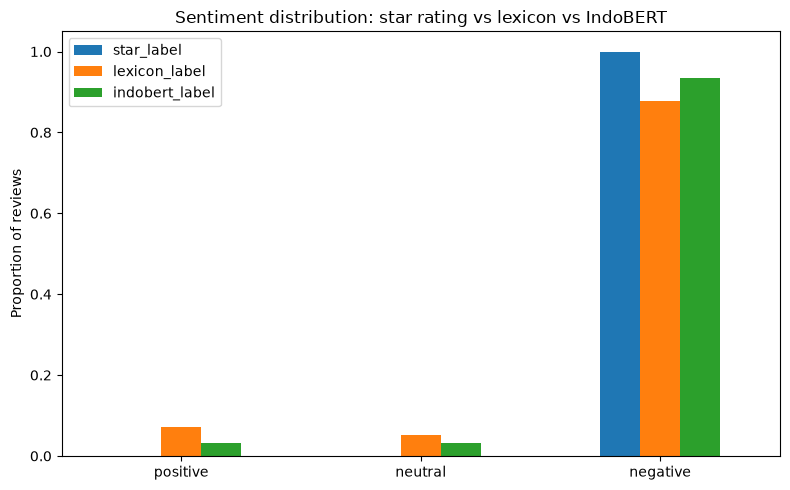

,star_label,lexicon_label,indobert_label
positive,0.0,0.0715,0.033
neutral,0.0,0.0520,0.032
negative,1.0,0.8765,0.935


In [48]:
compare = pd.DataFrame({
    "star_label": df["star_label"].value_counts(normalize=True),
    "lexicon_label": df["lexicon_label"].value_counts(normalize=True),
    "indobert_label": df["indobert_label"].value_counts(normalize=True),
}).fillna(0)

compare = compare.reindex(["positive", "neutral", "negative"])
compare.plot(kind="bar", figsize=(8, 5))
plt.ylabel("Proportion of reviews")
plt.title("Sentiment distribution: star rating vs lexicon vs IndoBERT")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

compare

## 2. Sentiment trend over time

Using IndoBERT's label since it's the most reliable of the three. A spike in negative sentiment is worth checking against release notes / known incidents.

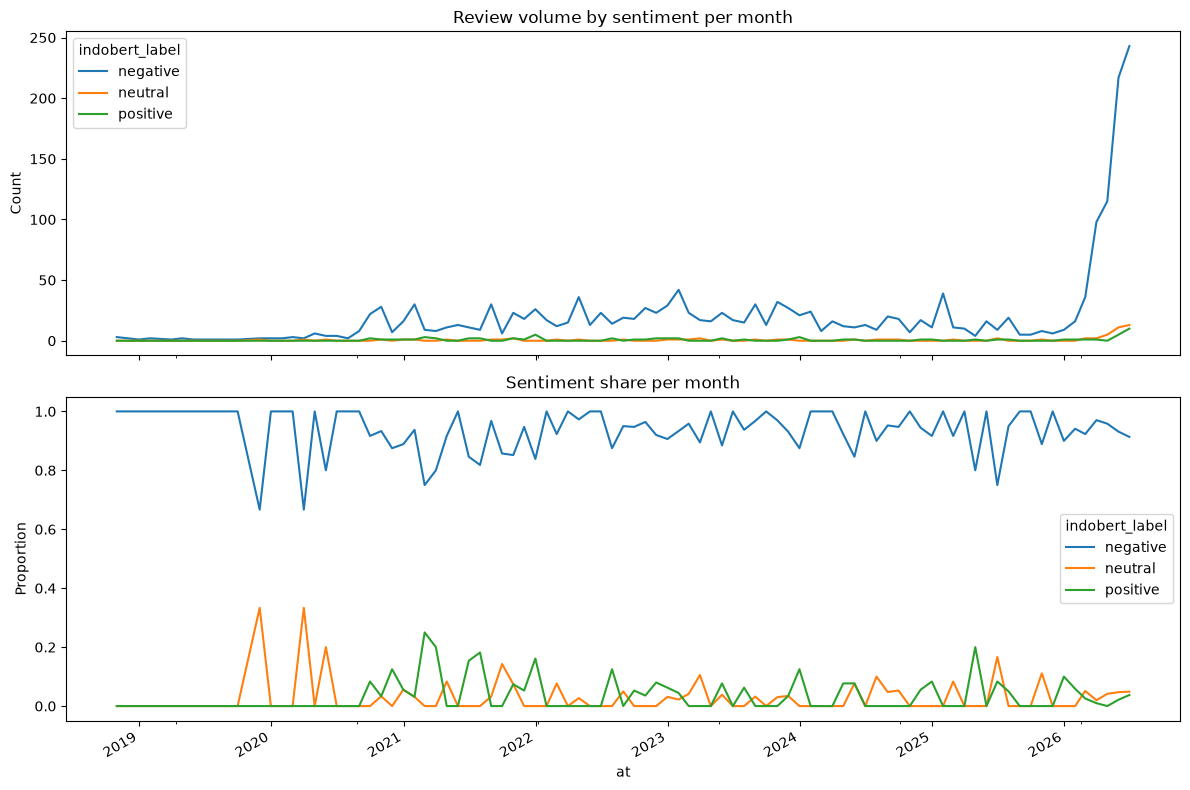

In [51]:
monthly = (
    df.dropna(subset=["at"])
      .set_index("at")
      .groupby([pd.Grouper(freq="ME"), "indobert_label"])
      .size()
      .unstack(fill_value=0)
)

monthly_pct = monthly.div(monthly.sum(axis=1), axis=0)

fig, axes = plt.subplots(2, 1, figsize=(12, 8), sharex=True)

monthly.plot(ax=axes[0])
axes[0].set_title("Review volume by sentiment per month")
axes[0].set_ylabel("Count")

monthly_pct.plot(ax=axes[1])
axes[1].set_title("Sentiment share per month")
axes[1].set_ylabel("Proportion")

plt.tight_layout()
plt.show()

## 3. Sentiment by app version

Which version had the worst sentiment share? Only versions with a reasonable review count are shown (low-volume versions produce noisy percentages).

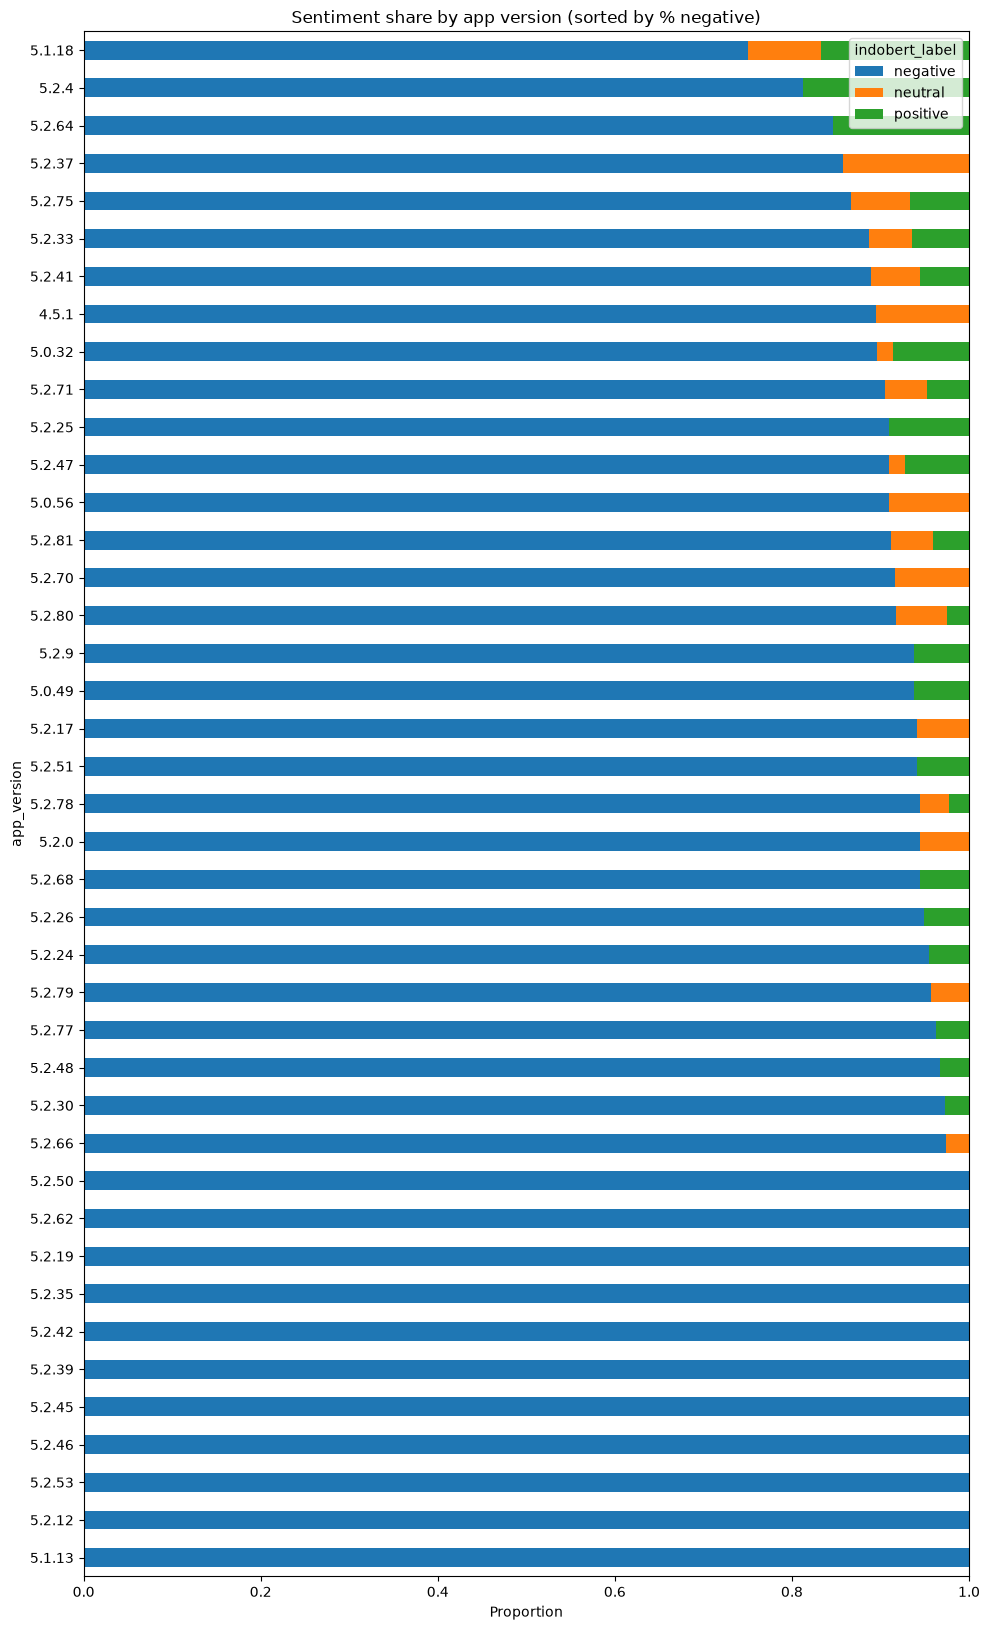

indobert_label,negative,neutral,positive
app_version,,,
5.1.13,1.000000,0.000000,0.000000
5.2.12,1.000000,0.000000,0.000000
5.2.53,1.000000,0.000000,0.000000
5.2.46,1.000000,0.000000,0.000000
5.2.45,1.000000,0.000000,0.000000
5.2.39,1.000000,0.000000,0.000000
5.2.42,1.000000,0.000000,0.000000
5.2.35,1.000000,0.000000,0.000000
5.2.19,1.000000,0.000000,0.000000


In [52]:
MIN_REVIEWS_PER_VERSION = 10

version_counts = df["app_version"].value_counts()
valid_versions = version_counts[version_counts >= MIN_REVIEWS_PER_VERSION].index

by_version = (
    df[df["app_version"].isin(valid_versions)]
    .groupby(["app_version", "indobert_label"])
    .size()
    .unstack(fill_value=0)
)
by_version_pct = by_version.div(by_version.sum(axis=1), axis=0).sort_values("negative", ascending=False)

by_version_pct.plot(kind="barh", stacked=True, figsize=(10, max(4, len(by_version_pct) * 0.4)))
plt.xlabel("Proportion")
plt.title("Sentiment share by app version (sorted by % negative)")
plt.tight_layout()
plt.show()

by_version_pct

## 4. Top keywords / phrases per sentiment class

Using the lightly-cleaned, unstemmed text — bigrams often carry more meaning than single words ("live chat", "tidak bisa", "customer service").

In [56]:
from sklearn.feature_extraction.text import CountVectorizer

def top_ngrams(texts, n=20, ngram_range=(1, 2)):
    vec = CountVectorizer(ngram_range=ngram_range, min_df=3)
    X = vec.fit_transform(texts.astype(str))
    counts = X.sum(axis=0).A1
    freq = pd.Series(counts, index=vec.get_feature_names_out()).sort_values(ascending=False)
    return freq.head(n)

negative_texts = df.loc[df["indobert_label"] == "negative", "clean_unstemmed"]
positive_texts = df.loc[df["indobert_label"] == "positive", "clean_unstemmed"]

print("=== Top terms in NEGATIVE reviews ===")
print(top_ngrams(negative_texts))

ModuleNotFoundError: No module named 'sklearn'

In [ ]:
print("=== Top terms in POSITIVE reviews ===")
print(top_ngrams(positive_texts))

## 5. Word cloud (negative reviews)

Quick visual gut-check — good for a slide/report, not for real analysis (a word cloud has no notion of statistical significance, just raw frequency).

In [57]:
from wordcloud import WordCloud

text_blob = " ".join(negative_texts)
wc = WordCloud(width=1000, height=500, background_color="white", collocations=True).generate(text_blob)

plt.figure(figsize=(12, 6))
plt.imshow(wc, interpolation="bilinear")
plt.axis("off")
plt.title("Most frequent words — negative reviews")
plt.show()

ModuleNotFoundError: No module named 'wordcloud'

## 6. Aspect tagging — what are people actually complaining about?

This is the most actionable part of this whole notebook. Instead of one big "negative" bucket, we tag each review against known PLN Mobile complaint categories using keyword rules. A review can match more than one aspect (e.g. a review about failed token purchase AND poor CS response).

**Extend `aspect_keywords` as you read more of your negative reviews** — this list is a starting point based on common complaint patterns, not exhaustive.

In [ ]:
aspect_keywords = {
    "login_otp": ["login", "otp", "masuk", "verifikasi", "daftar", "password", "kata sandi", "akun"],
    "token_pembelian": ["token", "beli", "pembelian", "kwh", "meter"],
    "pembayaran": ["bayar", "pembayaran", "transaksi", "saldo", "refund", "tagihan", "va bank"],
    "notifikasi_pemadaman": ["notif", "notifikasi", "pemberitahuan", "padam", "pemadaman", "listrik mati"],
    "crash_error": ["error", "bug", "crash", "lemot", "lambat", "force close", "keluar sendiri", "tidak bisa dibuka", "loading"],
    "customer_service": ["cs ", "customer service", "admin", "live chat", "respon", "layanan", "call center", "123"],
    "fitur_request": ["fitur", "tambahkan", "seharusnya ada", "belum ada", "semoga ada"],
    "poin_promo": ["poin", "reward", "hadiah", "promo", "diskon", "cashback"],
}

def tag_aspects(text, aspect_keywords=aspect_keywords):
    text = " " + str(text).lower() + " "
    tags = [aspect for aspect, kws in aspect_keywords.items() if any(kw in text for kw in kws)]
    return tags if tags else ["lainnya"]

negative_df = df[df["indobert_label"] == "negative"].copy()
negative_df["aspects"] = negative_df["clean_unstemmed"].apply(tag_aspects)

# explode so each aspect gets its own row for counting
aspect_counts = negative_df.explode("aspects")["aspects"].value_counts()
aspect_pct = (aspect_counts / len(negative_df) * 100).round(1)

print(f"Total negative reviews: {len(negative_df)}")
print("\n% of negative reviews mentioning each aspect (can exceed 100% since reviews can match multiple aspects):")
aspect_pct

In [ ]:
aspect_pct.sort_values().plot(kind="barh", figsize=(8, 5))
plt.xlabel("% of negative reviews")
plt.title("What negative reviews are actually about")
plt.tight_layout()
plt.show()

## 7. Sample reviews per aspect
Read a few from each category to sanity-check the tagging and pull real quotes for a report.

In [ ]:
ASPECT_TO_INSPECT = "customer_service"  # change this to explore other aspects

matching = negative_df[negative_df["aspects"].apply(lambda tags: ASPECT_TO_INSPECT in tags)]
print(f"{len(matching)} negative reviews tagged '{ASPECT_TO_INSPECT}'")

for _, row in matching.sample(min(5, len(matching)), random_state=1).iterrows():
    print(f"[{row['score']}★] {row['content']}")
    print("-" * 80)

## 8. Aspect trend over time
Is a particular complaint category getting worse recently?

In [ ]:
aspect_monthly = (
    negative_df.dropna(subset=["at"])
    .explode("aspects")
    .set_index("at")
    .groupby([pd.Grouper(freq="ME"), "aspects"])
    .size()
    .unstack(fill_value=0)
)

aspect_monthly.plot(figsize=(12, 6))
plt.title("Negative review aspects over time")
plt.ylabel("Count")
plt.legend(bbox_to_anchor=(1.02, 1), loc="upper left")
plt.tight_layout()
plt.show()

## 9. Save summary outputs
These are the tables you'd actually put in a report.

In [ ]:
aspect_pct.to_csv("summary_aspect_breakdown.csv", header=["pct_of_negative_reviews"])
by_version_pct.to_csv("summary_sentiment_by_version.csv")
monthly_pct.to_csv("summary_sentiment_by_month.csv")
negative_df[["review_id", "content", "score", "at", "app_version", "aspects"]].to_csv("negative_reviews_tagged.csv", index=False)

print("Saved: summary_aspect_breakdown.csv, summary_sentiment_by_version.csv, summary_sentiment_by_month.csv, negative_reviews_tagged.csv")